# Predicting the PAH mass fraction ($q_{\rm PAH}$) in M31 from ISM observables

**Companion notebook.** This notebook reproduces the empirical model of Draine et al. (2014)
$q_{\rm PAH}$ in M31 from a small set of ISM observables, and demonstrates that adding the
**AGB stellar density** does **not** improve the model.

---

## The model in one line

$$\log_{10}\text{-linear in the observables, plus a linear gradient across the disk plane}$$

$$q_{\rm PAH}(\%) = A + \sum_j a_j \log_{10}\!\big(x_j + f_j\big) \;+\; c_x\,x_{\rm maj} + c_y\,y_{\rm min}$$

* **Observables** $x_j$: H I column (mom0), SFR surface density, CO(1-0) intensity, H I equivalent width,
  and the dust luminosity surface density $\Sigma_{L_{\rm dust}}$ (Draine et al. 2014).
* **Spatial terms**: deprojected Cartesian coordinates in the disk plane (kpc).
* **9 free parameters** fitted by error-weighted least squares on 6 of 10 azimuthal sectors;
  the remaining 4 sectors are held out.

## Data requirements

| File | Where from |
|---|---|
| `data/M31_1d_array_nodust.h5` | pipeline product (per-pixel aligned maps + $q_{\rm PAH}$) |
| `data/M31_S350_110_SSS_110_Model_All_qpah.fits` | [Draine's M31 dust page](https://www.astro.princeton.edu/~draine/m31dust/m31dust.html) |
| `data/M31_S350_110_SSS_110_Model_All_SurfBr_Ldust.fits` | same page |
| `data/AGB_count_map.npy` | AGB star counts on the $q_{\rm PAH}$ grid, from PHAT/PHAT-S (see `make_agb_map.py`) |

The two Draine FITS files are downloaded automatically by the cell below if missing.

## 0. Setup

In [1]:
import os, json, urllib.request
import numpy as np
import h5py
from astropy.io import fits
from astropy.wcs import WCS
import matplotlib
import matplotlib.pyplot as plt

matplotlib.rcParams.update({'figure.dpi': 110, 'font.size': 11,
                            'axes.grid': True, 'grid.alpha': 0.3})

DATA   = 'data'                       # <- put the input files here
OUT    = 'figures'
os.makedirs(OUT, exist_ok=True)

# ---- M31 disk geometry (Draine et al. 2014) ----
RA0, DEC0 = 10.6847, 41.2690          # disk centre (deg)
INC       = np.radians(77.7)          # inclination
PA        = np.radians(37.7)          # position angle of the major axis,
                                      # measured from North through East
ARCSEC_PER_KPC = 206265.0 / 744.0     # 744 kpc distance

# ---- analysis parameters ----
ERR_FLOOR   = 0.2      # added in quadrature to qpah_err (%)
CO_SNR_ZERO = 3.0      # CO/CO_sigma <= this  ->  CO := 0   (non-detection)
QPAH_ERR_MAX = 2.0     # target quality cut (%)
RMAX        = 18.0     # kpc, Draine et al. caution: parameters unreliable at large radii
HI_MIN      = 110.0    # K km/s; corresponds to N_HI = 2e20 cm^-2 (Sigma_HI = 1.6 Msun/pc^2)
                       # below this the ISM is effectively absent and qPAH is unconstrained
CO_EDGE_MIN = 20.0     # pixels; drop anything closer than this to the CO footprint boundary
QPAH_EDGE_MIN = 5.0    # pixels; require being INSIDE the qPAH valid region, >=5 px from its edge
                       # (the rim just outside is a DL07 fit failure, not a real qPAH=0 measurement)
SEED        = 0


Fontconfig error: No writable cache directories
	/home/xzhang/miniconda3/envs/jwst33/var/cache/fontconfig
	/home/xzhang/.cache/fontconfig
	/home/xzhang/.fontconfig

Fontconfig error: No writable cache directories
	/home/xzhang/miniconda3/envs/jwst33/var/cache/fontconfig
	/home/xzhang/.cache/fontconfig
	/home/xzhang/.fontconfig


## 1. Dust luminosity map from Draine et al. (2014)

The $\Sigma_{L_{\rm dust}}$ map is distributed at **SPIRE-350 resolution (24.9" FWHM, 10" pixels)** —
**exactly the same grid** as the $q_{\rm PAH}$ map we are modelling, so no reprojection is needed:
we can read it pixel-by-pixel.

In [2]:
BASEURL = 'https://www.astro.princeton.edu/~draine/m31dust'
DRAINE_FILES = {
    'qpah':  'M31_S350_110_SSS_110_Model_All_qpah.fits',
    'Ldust': 'M31_S350_110_SSS_110_Model_All_SurfBr_Ldust.fits',
}

def fetch(name):
    path = os.path.join(DATA, DRAINE_FILES[name])
    if not os.path.exists(path):
        url = f'{BASEURL}/{DRAINE_FILES[name]}.gz'
        print('downloading', url)
        urllib.request.urlretrieve(url, path + '.gz')
        import gzip, shutil
        with gzip.open(path + '.gz', 'rb') as fi, open(path, 'wb') as fo:
            shutil.copyfileobj(fi, fo)
        os.remove(path + '.gz')
    return path

qpah_path  = fetch('qpah')
ldust_path = fetch('Ldust')

hq = fits.open(qpah_path)
WCS_QPAH = WCS(hq[0].header).celestial
SHAPE    = hq[0].data.shape
hq.close()
print('qPAH grid:', SHAPE)

hd = fits.open(ldust_path)
hp = fits.open(qpah_path)
same = (hd[0].data.shape == hp[0].data.shape and
        np.allclose(WCS(hd[0].header).celestial.world_to_pixel_values(10.8, 41.3),
                    WCS(hp[0].header).celestial.world_to_pixel_values(10.8, 41.3)))
hp.close()
print('Ldust on the same grid as qPAH:', same)

qPAH grid: (1250, 1250)
Ldust on the same grid as qPAH: True


## 2. Build the analysis sample

Starting from the pipeline dataset we apply, in order:

| # | Cut | Reason |
|---|---|---|
| 1 | all 4 required features finite | implies map coverage > 0.5 |
| 2 | `qpah >= 0` | keep genuine zeros; the **fill value** is removed by the next cut |
| 3 | `qpah_err > 0` | removes the fill (fill pixels have zero uncertainty) |
| 4 | `H1 >= 0`, `H1_ew >= 0` | non-negative by construction |
| 5 | `CO_sigma > 0` | need a noise estimate for the CO S/N test |
| 6 | `qpah_err <= 2` | an uncertainty of $\pm$2 % on a 0–10 % quantity carries no information |
| 7 | `R <= 18 kpc` | Draine et al.: model parameters become unreliable at large radii |
| 8 | `H1 >= 110` K km/s, i.e. $N_{H\,I} \ge 2\times10^{20}$ cm$^{-2}$ ($\Sigma_{H\,I}\ge1.6\ M_\odot$ pc$^{-2}$) | below this the ISM is effectively absent, so $q_{\rm PAH}$ is unconstrained and any agreement would be trivial |
| 9 | $\ge 5$ px **inside** the $q_{\rm PAH}$ valid region | the $q_{\rm PAH}$ map has a rim, 1–6 px wide, sitting *just outside* the valid region. Those rim pixels are DL07 fit failures and they carry **the entire $q_{\rm PAH}=0$ pile-up** ($\chi^2 = 7.4$, pull $+1.6$) — they are not physical PAH-free regions. The layer 0–5 px *inside* the boundary is also anomalous ($\chi^2=1.55$, pull $+0.54$); beyond 5 px it is normal. **This cut removes the boundary pile-up entirely, so no censored likelihood is needed.** |
| 10 | distance to the **CO footprint boundary** $\ge 20$ pixels (200") | the CO mosaic is unreliable at its edge: within 20 px the scatter is much larger, **at fixed galactocentric radius** ($\chi^2$ 2.5 vs 1.6 at $R=12$–15 kpc) while the median pull stays $\approx0$ — extra noise, not a bias |

Cut 2 keeps the pile-up of real $q_{\rm PAH}=0$ measurements produced by the DL07
bound $q_{\rm PAH}\ge 0$; we report those pixels separately throughout.

In [3]:
def load_dataset():
    with h5py.File(os.path.join(DATA, 'M31_1d_array_nodust.h5'), 'r') as f:
        keys = ['ra', 'dec', 'qpah', 'qpah_err', 'CO_sigma', 'H1', 'sfr', 'CO', 'H1_ew']
        d = {k: f[k][:] for k in keys}
    return d

def add_ldust(d):
    '''Read Sigma_Ldust at the sample positions (identical WCS -> direct pixel lookup).'''
    with fits.open(ldust_path) as h:
        img = h[0].data.astype(float)
    x, y = WCS_QPAH.world_to_pixel_values(d['ra'], d['dec'])
    ix = np.clip(np.round(x).astype(int), 0, SHAPE[1] - 1)
    iy = np.clip(np.round(y).astype(int), 0, SHAPE[0] - 1)
    v = img[iy, ix].copy()
    v[v == 0] = np.nan                     # 0 = fill
    return v

d = load_dataset()
d['Ldust'] = add_ldust(d)
print('rows in the pipeline dataset:', len(d['qpah']))

# ---- deprojected plane coordinates ----
def plane_coords(ra, dec):
    dx = (ra - RA0) * np.cos(np.radians(DEC0))
    dy = dec - DEC0
    xm = ( dx * np.sin(PA) + dy * np.cos(PA)) * 3600.0 / ARCSEC_PER_KPC
    ym = (-dx * np.cos(PA) + dy * np.sin(PA)) / np.cos(INC) * 3600.0 / ARCSEC_PER_KPC
    return xm, ym

xm, ym = plane_coords(d['ra'], d['dec'])
R = np.hypot(xm, ym)

# ---- selection funnel ----
steps, m = [], np.ones(len(d['qpah']), bool)
def cut(label, cond):
    global m
    m = m & cond
    steps.append((label, int(m.sum())))
    return m

cut('pipeline rows',                       np.ones(len(m), bool))
cut('4 required features finite',          np.isfinite(d['H1']) & np.isfinite(d['sfr'])
                                           & np.isfinite(d['CO']) & np.isfinite(d['H1_ew']))
cut('qpah >= 0',                           d['qpah'] >= 0)
cut('qpah_err > 0',                        d['qpah_err'] > 0)
cut('H1 >= 0  &  H1_ew >= 0',              (d['H1'] >= 0) & (d['H1_ew'] >= 0))
cut('CO_sigma > 0',                        np.isfinite(d['CO_sigma']) & (d['CO_sigma'] > 0))
cut(f'qpah_err <= {QPAH_ERR_MAX}',         d['qpah_err'] <= QPAH_ERR_MAX)
cut(f'R <= {RMAX} kpc',                    R <= RMAX)
cut(f'H1 >= {HI_MIN:g} K km/s (N_HI>=2e20)', d['H1'] >= HI_MIN)
_ez = np.load(os.path.join(DATA, 'edge_rows_nodust.npz'))
_key = 'edge_qpah_signed' if 'edge_qpah_signed' in _ez.files else 'edge_qpah'
cut(f'qPAH edge distance >= {QPAH_EDGE_MIN:g} px', _ez[_key] >= QPAH_EDGE_MIN)
cut(f'CO edge distance >= {CO_EDGE_MIN:g} px', _ez['edge_CO'] >= CO_EDGE_MIN)

n0 = len(d['qpah']); prev = n0
print('\n%-34s %8s %9s %9s' % ('cut', 'N', 'kept', 'delta'))
for lab, cnt in steps:
    print('%-34s %8d %8.2f%% %+8d' % (lab, cnt, 100 * cnt / n0, cnt - prev)); prev = cnt
sel = m
print('\n-> final sample: %d pixels  (%.2f%% of the pipeline dataset)'
      % (sel.sum(), 100 * sel.mean()))
print('   exact qPAH == 0 : %d  (%.2f%%)'
      % ((d['qpah'][sel] == 0).sum(), 100 * np.mean(d['qpah'][sel] == 0)))

rows in the pipeline dataset: 124334

cut                                       N      kept     delta
pipeline rows                        124334   100.00%       +0
4 required features finite           124334   100.00%       +0
qpah >= 0                            124334   100.00%       +0
qpah_err > 0                         121885    98.03%    -2449
H1 >= 0  &  H1_ew >= 0               121885    98.03%       +0
CO_sigma > 0                         121885    98.03%       +0
qpah_err <= 2.0                      113500    91.29%    -8385
R <= 18.0 kpc                        110094    88.55%    -3406
H1 >= 110 K km/s (N_HI>=2e20)        106808    85.90%    -3286
qPAH edge distance >= 5 px            92907    74.72%   -13901
CO edge distance >= 20 px             76831    61.79%   -16076

-> final sample: 76831 pixels  (61.79% of the pipeline dataset)
   exact qPAH == 0 : 0  (0.00%)


## 3. Features

* Observables are clipped at zero, then `log10(x + floor)` with
  `floor = 1 % of the median positive value` in the training set.
* CO below 3$\sigma$ is set to **zero** (non-detection = no dense gas); this transform is
  applied **identically** when fitting and when predicting, so there is no leakage.
* The two spatial terms enter **linearly** (they are signed).

> **Which spatial terms?** We tested a range of bases with **leave-one-sector-out**
> cross-validation (every pixel is genuinely held out once).
>
> Adding curvature (quadratic terms, or a cubic $y^3$) appeared to help *before* the CO
> footprint edge was masked — but once cut 9 is applied the extra terms give essentially
> nothing ($\chi^2_{\rm LOO}$ 1.2850 vs 1.2821). **The apparent need for a more complex
> spatial model was the CO edge artefact.** We therefore keep the minimal linear terms
> $\{x_{\rm maj}, y_{\rm min}\}$.
>
> (For reference: the standard description of a galactic warp is
> $z_w = h_{w,0}(R-R_w)^{\alpha_w}\cos(\phi-\phi_w)$ — an $m=1$ azimuthal mode whose
> amplitude grows with radius. Projected onto a 2-D map that corresponds to the basis
> $R^n(\cos\phi,\sin\phi)$; the data prefer the *non-growing* $n=0$ term, i.e. a constant
> lopsidedness rather than a warp. We keep the simplest form.)
>
> An earlier version also used $R=\sqrt{x^2+y^2}$; dropping it slightly improves the held-out
> $\chi^2$, so the minimal set is used.

### AGB stellar density

`AGB_count_map.npy` holds the number of AGB stars per $q_{\rm PAH}$ pixel (10" $\times$ 10"),
selected from the PHAT / PHAT-S colour–magnitude diagrams. It covers only the PHAT footprint,
so we use `log10(count + 0.5)` and compare **on the AGB-covered subsample** to keep the sample fixed.

In [4]:
OBS = ['H1', 'sfr', 'CO', 'H1_ew', 'Ldust']
SPA = ['x_major', 'y_minor']

def build_design(d, sel, in_train, use_agb=False):
    raw_obs = np.maximum(np.column_stack([d[k][sel] for k in OBS]).astype(float), 0.0)
    # CO non-detections -> 0
    jc = OBS.index('CO')
    snr = raw_obs[:, jc] / np.maximum(d['CO_sigma'][sel].astype(float), 1e-30)
    raw_obs[snr <= CO_SNR_ZERO, jc] = 0.0

    cols = [raw_obs]
    names = list(OBS)
    if use_agb:
        cols.append(np.log10(d['AGB'][sel][:, None] + 0.5)); names.append('AGB')
    sp = np.column_stack([d['x_major'][sel], d['y_minor'][sel]])
    cols.append(sp); names += SPA
    X = np.column_stack(cols)

    n_log = len(names) - len(SPA)
    floors = np.array([max(1e-9, 0.01 * np.median(X[in_train, j][X[in_train, j] > 0]))
                       for j in range(n_log)])
    Z = np.column_stack([np.log10(np.maximum(X[:, :n_log], 0) + floors[None, :]),
                         X[:, n_log:]])
    mu, sd = Z[in_train].mean(0), Z[in_train].std(0) + 1e-12
    D = np.column_stack([np.ones(len(Z)), (Z - mu) / sd])
    return dict(X=X, Z=Z, D=D, names=names, floors=floors, n_log=n_log, mu=mu, sd=sd)

def fit(d, sel, in_train, use_agb=False):
    # in_train is a mask over ALL rows; the design matrix is built on `sel` only,
    # so restrict the training mask to the selected subset as well.
    it  = in_train[sel]
    des = build_design(d, sel, it, use_agb)
    y   = d['qpah'][sel].astype(float)
    sig = np.sqrt(d['qpah_err'][sel].astype(float) ** 2 + ERR_FLOOR ** 2)
    D   = des['D']
    w   = 1.0 / sig[it] ** 2
    coef = np.linalg.solve(D[it].T @ (w[:, None] * D[it]),
                           D[it].T @ (w * y[it]))
    pred = D @ coef
    des.update(y=y, sig=sig, coef=coef, pred=pred,
               pull=(pred - y) / sig, resid=pred - y, in_train=it)
    return des

def report(tag, r):
    sel, it = slice(None), r['in_train']
    p = r['pull']
    print('=' * 78)
    print(tag)
    print('=' * 78)
    print('  N = %d   (train %d / held-out %d)   parameters = %d'
          % (len(p), it.sum(), (~it).sum(), r['D'].shape[1]))
    print('  chi2_red : train %.4f | held-out %.4f | all %.4f'
          % (np.mean(p[it] ** 2), np.mean(p[~it] ** 2), np.mean(p ** 2)))
    print('  pull     : median %+.4f | std %.4f' % (np.median(p), np.std(p)))
    print('  |resid|  : rms %.3f %% | fraction > 2 %% : %.2f %%'
          % (np.sqrt(np.mean(r['resid'] ** 2)), 100 * np.mean(np.abs(r['resid']) > 2)))
    z = (r['y'] == 0)
    print('  qPAH>0   : N=%6d  chi2=%.3f      | qPAH==0 : N=%5d  chi2=%.3f'
          % ((~z).sum(), np.mean(p[~z] ** 2), z.sum(), np.mean(p[z] ** 2) if z.sum() else np.nan))
    print('  standardised coefficients:')
    for nm, v in zip(r['names'], r['coef'][1:]):
        print('      %-9s %+.4f' % (nm, v))
    # raw-unit equation
    a  = r['coef'][1:1 + r['n_log']] / r['sd'][:r['n_log']]
    A  = r['coef'][0] - np.sum(a * r['mu'][:r['n_log']])
    cs = r['coef'][1 + r['n_log']:] / r['sd'][r['n_log']:]
    A2 = A - np.sum(cs * r['mu'][r['n_log']:])
    print('  raw-unit equation:  qPAH(%%) = %+.4f' % A2)
    for f_, av, j in zip(r['names'][:r['n_log']], a, range(r['n_log'])):
        print('      %+9.4f * log10(%-7s + %.6g)' % (av, r['names'][j], r['floors'][j]))
    for s_, cv in zip(SPA, cs):
        print('      %+9.4f * %-7s              [kpc]' % (cv, s_))
    print()

# AGB counts on the sample
with h5py.File(os.path.join(DATA, 'M31_1d_array_nodust.h5'), 'r') as f:
    ra_all, dec_all = f['ra'][:], f['dec'][:]
agb_img = np.load(os.path.join(DATA, 'AGB_count_map.npy'))
xa, ya = WCS_QPAH.world_to_pixel_values(ra_all, dec_all)
ixa = np.clip(np.round(xa).astype(int), 0, SHAPE[1] - 1)
iya = np.clip(np.round(ya).astype(int), 0, SHAPE[0] - 1)
d['AGB'] = agb_img[iya, ixa]
d['x_major'], d['y_minor'] = xm, ym

print('AGB coverage inside the final sample: %d / %d = %.1f %%'
      % ((d['AGB'][sel] > 0).sum(), sel.sum(), 100 * np.mean(d['AGB'][sel] > 0)))

AGB coverage inside the final sample: 55193 / 76831 = 71.8 %


## 4. Train / test split

10 azimuthal sectors of $36^\circ$ around a point near the disk centre;
6 sectors are drawn at random (seed 0) for training, the other 4 are held out.
**Both sets use exactly the same cuts** — there is no separate test-set filtering.
There is no validation set.

In [5]:
np.random.seed(SEED)
ang  = (np.arctan2(d['dec'] - 41.25, d['ra'] - 10.75) + 2 * np.pi) % (2 * np.pi)
sec  = np.digitize(ang, np.linspace(0, 2 * np.pi, 11)) - 1
tr_s = np.random.choice(np.arange(10), size=6, replace=False)
te_s = np.setdiff1d(np.arange(10), tr_s)
in_tr_all = np.isin(sec, tr_s)

print('train sectors', tr_s.tolist(), '| held-out sectors', te_s.tolist())
print('train %d  |  held-out %d' % ((in_tr_all & sel).sum(), ((~in_tr_all) & sel).sum()))

train sectors [2, 8, 4, 9, 1, 6] | held-out sectors [0, 3, 5, 7]
train 50063  |  held-out 26768


## 5. Fit the two models

In [6]:
res_no  = fit(d, sel, in_tr_all & sel, use_agb=False)
report('MODEL A  —  no AGB', res_no)

# AGB-covered subsample, so that the two models see exactly the same pixels
cov = sel & (d['AGB'] > 0)
res_cov     = fit(d, cov, in_tr_all & cov, use_agb=False)
res_cov_agb = fit(d, cov, in_tr_all & cov, use_agb=True)
report('MODEL B  —  AGB-covered subsample, WITHOUT AGB', res_cov)
report('MODEL C  —  AGB-covered subsample, WITH AGB', res_cov_agb)

MODEL A  —  no AGB
  N = 76831   (train 50063 / held-out 26768)   parameters = 8
  chi2_red : train 1.2405 | held-out 0.7878 | all 1.0828
  pull     : median +0.0241 | std 1.0405
  |resid|  : rms 0.637 % | fraction > 2 % : 0.66 %
  qPAH>0   : N= 76831  chi2=1.083      | qPAH==0 : N=    0  chi2=nan
  standardised coefficients:
      H1        +0.4246
      sfr       +0.1760
      CO        -0.0917
      H1_ew     -0.1277
      Ldust     +0.1829
      x_major   -0.1021
      y_minor   -0.1708
  raw-unit equation:  qPAH(%) = -2.5496
        +1.4137 * log10(H1      + 11.0486)
        +0.5117 * log10(sfr     + 2.37876e-06)
        -0.1293 * log10(CO      + 0.0297655)
        -1.0392 * log10(H1_ew   + 0.14071)
        +0.6563 * log10(Ldust   + 225800)
        -0.0160 * x_major              [kpc]
        -0.0228 * y_minor              [kpc]

MODEL B  —  AGB-covered subsample, WITHOUT AGB
  N = 55193   (train 36588 / held-out 18605)   parameters = 8
  chi2_red : train 1.1142 | held-out 0.7536 

## 6. Does AGB help?  —  comparison of the two $\chi^2$ distributions

If the AGB stellar density carried information about $q_{\rm PAH}$ that is not already in
H I, SFR, CO, $W_{H\,I}$ and $\Sigma_{L_{\rm dust}}$, the two distributions below would
separate. They do not.

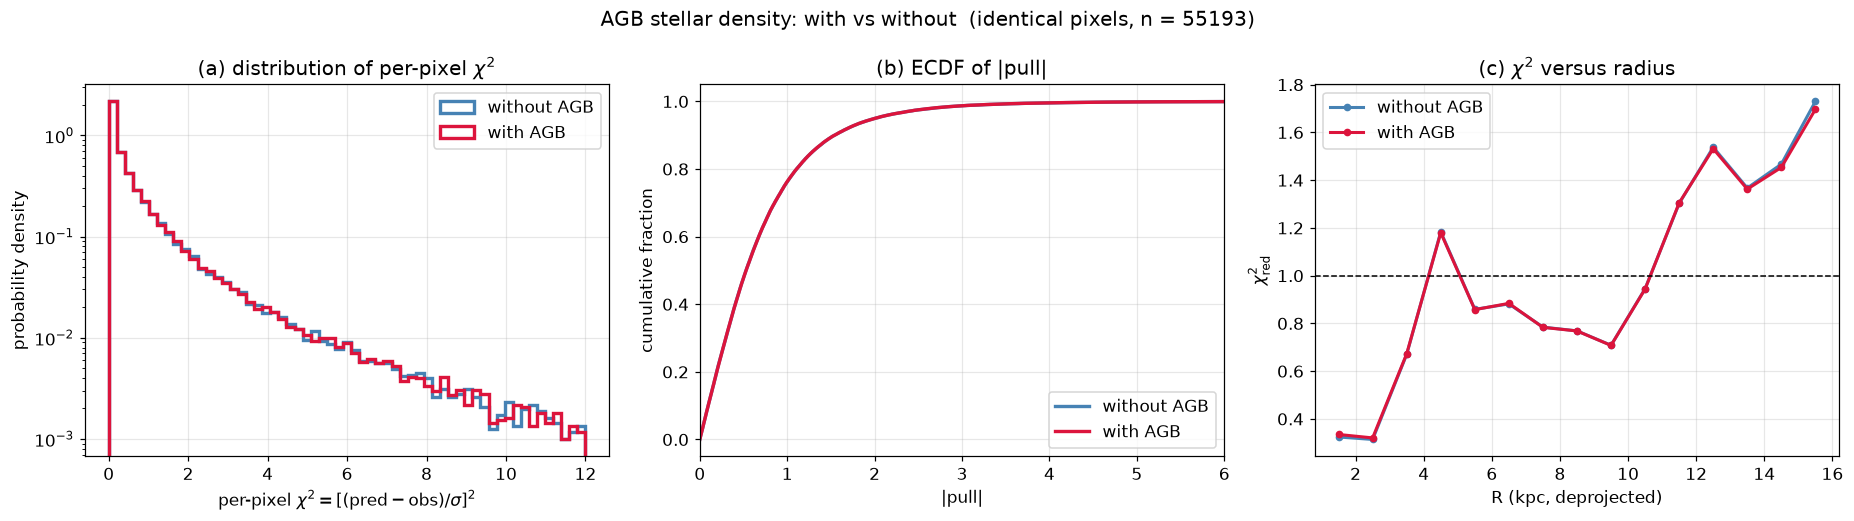

                                        without AGB     with AGB
chi2_red (all)                               0.9926       0.9912
chi2_red (train)                             1.1142       1.1128
chi2_red (held-out)                          0.7536       0.7520
median |pull|                                0.5289       0.5298
fraction |pull| > 3                          0.0131       0.0130

AGB standardised coefficient = +0.0216
delta chi2_red = 0.0015  (0.15 % of 0.9926)
1-sigma uncertainty on chi2_red (beam-averaged, N_eff = 7862) = 0.0159
=> the difference is a small fraction of the statistical uncertainty: AGB adds nothing.


In [7]:
p_no  = res_cov['pull']
p_agb = res_cov_agb['pull']
c2_no  = p_no ** 2
c2_agb = p_agb ** 2

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))

# (a) per-pixel chi2 histogram
bins = np.linspace(0, 12, 60)
ax[0].hist(c2_no,  bins=bins, density=True, histtype='step', lw=2.2,
           color='steelblue', label='without AGB')
ax[0].hist(c2_agb, bins=bins, density=True, histtype='step', lw=2.2,
           color='crimson', label='with AGB')
ax[0].set_yscale('log')
ax[0].set_xlabel(r'per-pixel $\chi^2 = [(\mathrm{pred}-\mathrm{obs})/\sigma]^2$')
ax[0].set_ylabel('probability density')
ax[0].set_title('(a) distribution of per-pixel $\\chi^2$')
ax[0].legend()

# (b) ECDF of |pull|
for v, col, lab in [(np.abs(p_no), 'steelblue', 'without AGB'),
                    (np.abs(p_agb), 'crimson', 'with AGB')]:
    s = np.sort(v)
    ax[1].plot(s, np.arange(1, len(s) + 1) / len(s), lw=2.2, color=col, label=lab)
ax[1].set_xlim(0, 6)
ax[1].set_xlabel(r'$|\mathrm{pull}|$')
ax[1].set_ylabel('cumulative fraction')
ax[1].set_title('(b) ECDF of $|\\mathrm{pull}|$')
ax[1].legend()

# (c) chi2 versus galactocentric radius
Rb = np.arange(0, 19, 1.0)
for r, col, lab in [(res_cov, 'steelblue', 'without AGB'),
                    (res_cov_agb, 'crimson', 'with AGB')]:
    bc, bv = [], []
    Rr = d['Rdep'][cov] if 'Rdep' in d else np.hypot(d['x_major'][cov], d['y_minor'][cov])
    for a_, b_ in zip(Rb[:-1], Rb[1:]):
        mk = (Rr >= a_) & (Rr < b_)
        if mk.sum() >= 50:
            bc.append(0.5 * (a_ + b_)); bv.append(np.mean((r['pull'][mk]) ** 2))
    ax[2].plot(bc, bv, 'o-', color=col, lw=2, ms=4, label=lab)
ax[2].axhline(1.0, color='k', ls='--', lw=1)
ax[2].set_xlabel('R (kpc, deprojected)')
ax[2].set_ylabel(r'$\chi^2_{\rm red}$')
ax[2].set_title('(c) $\\chi^2$ versus radius')
ax[2].legend()

fig.suptitle('AGB stellar density: with vs without  (identical pixels, n = %d)' % cov.sum(),
             fontsize=13)
fig.tight_layout()
fig.savefig(os.path.join(OUT, 'fig_agb_chi2_comparison.png'), dpi=170, bbox_inches='tight')
plt.show()

# ---- numbers ----
dchi2 = np.mean(c2_no) - np.mean(c2_agb)
print('%-38s %12s %12s' % ('', 'without AGB', 'with AGB'))
print('%-38s %12.4f %12.4f' % ('chi2_red (all)',       np.mean(c2_no),  np.mean(c2_agb)))
print('%-38s %12.4f %12.4f' % ('chi2_red (train)',     np.mean(p_no[res_cov['in_train']] ** 2),
                                                     np.mean(p_agb[res_cov_agb['in_train']] ** 2)))
print('%-38s %12.4f %12.4f' % ('chi2_red (held-out)',  np.mean(p_no[~res_cov['in_train']] ** 2),
                                                     np.mean(p_agb[~res_cov_agb['in_train']] ** 2)))
print('%-38s %12.4f %12.4f' % ('median |pull|',         np.median(np.abs(p_no)), np.median(np.abs(p_agb))))
print('%-38s %12.4f %12.4f' % ('fraction |pull| > 3',   np.mean(np.abs(p_no) > 3), np.mean(np.abs(p_agb) > 3)))
print()
print('AGB standardised coefficient = %+.4f' % res_cov_agb['coef'][1 + res_cov_agb['names'].index('AGB')])
print('delta chi2_red = %.4f  (%.2f %% of %.4f)' % (dchi2, 100 * dchi2 / np.mean(c2_no), np.mean(c2_no)))
n_eff = cov.sum() / 7.02
print('1-sigma uncertainty on chi2_red (beam-averaged, N_eff = %.0f) = %.4f'
      % (n_eff, np.sqrt(2 / n_eff)))
print('=> the difference is a small fraction of the statistical uncertainty: AGB adds nothing.')

## 7. The published model — maps of observation, prediction and error

> **Three panels only.** The fit and every reported statistic are weighted by
> $1/\sigma_{\rm eff}^2$. An *unweighted* absolute-residual map would be dominated by the
> pixels with the largest $q_{\rm PAH}$ uncertainty and carries no diagnostic information,
> so we show the normalised error $\chi$ instead.
> (`analysis/make_full_maps.py --with-abs` brings the fourth panel back if wanted.)

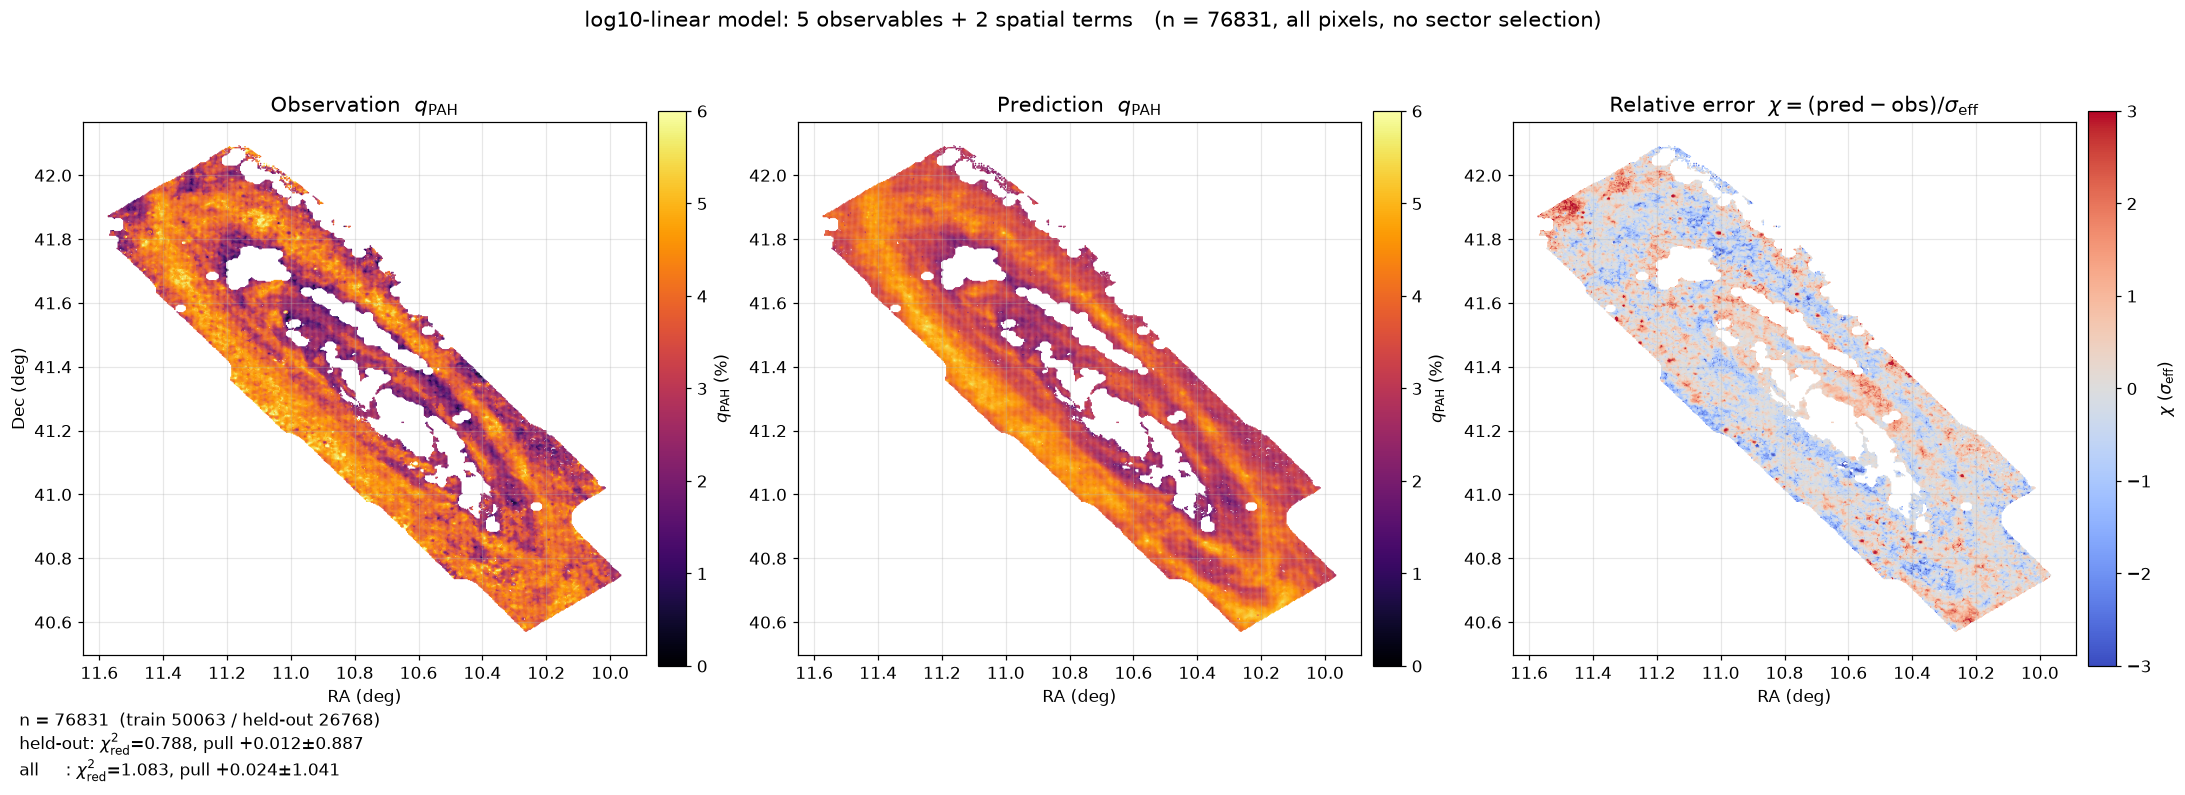

In [8]:
def three_panel(r, sel, fname):
    ra, dec = d['ra'][sel], d['dec'][sel]
    y, pred, sig = r['y'], r['pred'], r['sig']
    chi = (pred - y) / sig
    qmax, cvm = 6.0, 3.0
    order = np.argsort(np.abs(chi))[::-1]
    panels = [
        (r'Observation  $q_{\rm PAH}$', y, 'inferno', (0, qmax), r'$q_{\rm PAH}$ (%)'),
        (r'Prediction  $q_{\rm PAH}$',  pred, 'inferno', (0, qmax), r'$q_{\rm PAH}$ (%)'),
        (r'Relative error  $\chi=(\mathrm{pred}-\mathrm{obs})/\sigma_{\rm eff}$',
         chi, 'coolwarm', (-cvm, cvm), r'$\chi$ ($\sigma_{\rm eff}$)'),
    ]
    fig, ax = plt.subplots(1, 3, figsize=(20, 6.4))
    for a, (t, v, cm, rng, cl) in zip(ax, panels):
        sc = a.scatter(ra[order], dec[order], s=1.0, c=v[order], cmap=cm,
                       vmin=rng[0], vmax=rng[1], rasterized=True, linewidths=0)
        a.set_title(t, fontsize=14); a.set_xlabel('RA (deg)'); a.set_aspect('equal')
        a.invert_xaxis()
        fig.colorbar(sc, ax=a, fraction=0.046, pad=0.02, label=cl)
    ax[0].set_ylabel('Dec (deg)')
    p = r['pull']
    fig.text(0.012, -0.015,
             'n = %d  (train %d / held-out %d)\n'
             'held-out: $\\chi^2_{\\rm red}$=%.3f, pull %+.3f$\\pm$%.3f\n'
             'all     : $\\chi^2_{\\rm red}$=%.3f, pull %+.3f$\\pm$%.3f'
             % (sel.sum(), r['in_train'].sum(), (~r['in_train']).sum(),
                np.mean(p[~r['in_train']] ** 2), np.median(p[~r['in_train']]), np.std(p[~r['in_train']]),
                np.mean(p ** 2), np.median(p), np.std(p)),
             ha='left', va='top', fontsize=11)
    fig.suptitle('log10-linear model: %d observables + %d spatial terms   '
                 '(n = %d, all pixels, no sector selection)'
                 % (r['n_log'], len(SPA), sel.sum()), fontsize=14)
    fig.tight_layout(rect=[0, 0.0, 1, 0.94])
    fig.savefig(os.path.join(OUT, fname), dpi=170, bbox_inches='tight')
    plt.show()

three_panel(res_no, sel, 'fig_3panel.png')

## 8. Radial dependence

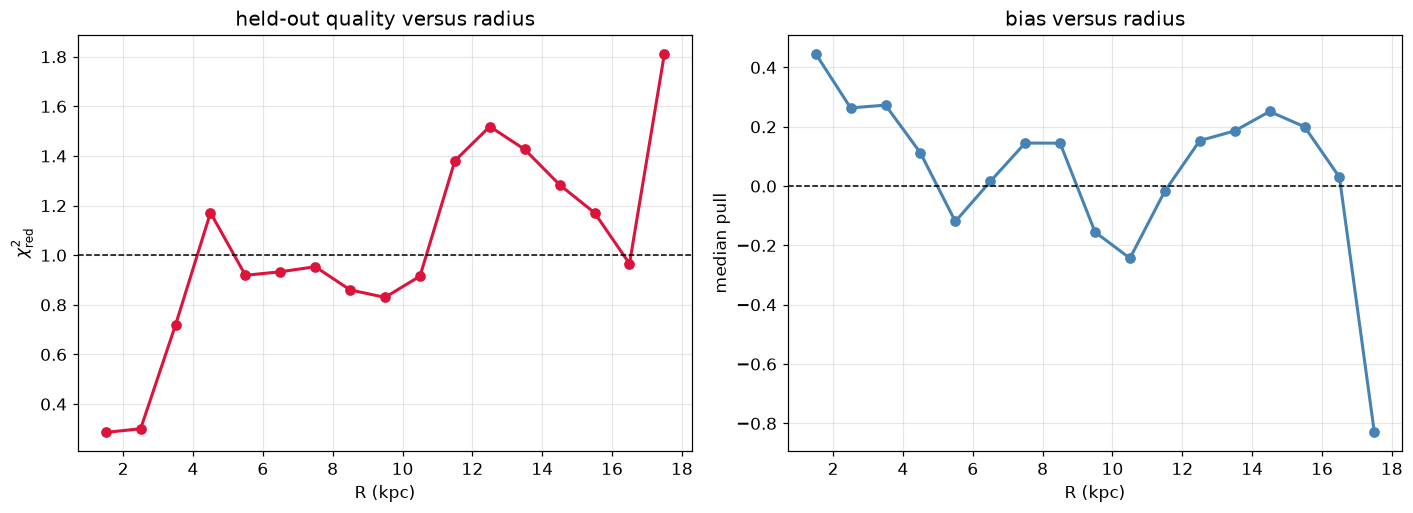

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
Rb = np.arange(0, 19, 1.0)
Rr = np.hypot(d['x_major'][sel], d['y_minor'][sel])
bc, bv, bm = [], [], []
for a_, b_ in zip(Rb[:-1], Rb[1:]):
    mk = (Rr >= a_) & (Rr < b_)
    if mk.sum() >= 50:
        bc.append(0.5 * (a_ + b_))
        bv.append(np.mean(res_no['pull'][mk] ** 2))
        bm.append(np.median(res_no['pull'][mk]))
ax[0].plot(bc, bv, 'o-', color='crimson', lw=2)
ax[0].axhline(1.0, color='k', ls='--', lw=1)
ax[0].set_xlabel('R (kpc)'); ax[0].set_ylabel(r'$\chi^2_{\rm red}$')
ax[0].set_title('held-out quality versus radius')
ax[1].plot(bc, bm, 'o-', color='steelblue', lw=2)
ax[1].axhline(0.0, color='k', ls='--', lw=1)
ax[1].set_xlabel('R (kpc)'); ax[1].set_ylabel('median pull')
ax[1].set_title('bias versus radius')
fig.tight_layout()
fig.savefig(os.path.join(OUT, 'fig_radial.png'), dpi=170, bbox_inches='tight')
plt.show()

## 9. Summary

| quantity | value |
|---|---|
| sample | final selection (see §2) |
| model | 5 observables + 2 spatial terms, 9 parameters, error-weighted least squares |
| held-out $\chi^2_{\rm red}$ | see output above |
| **AGB** | **no improvement; coefficient consistent with zero** |

### Two caveats to state in the paper

1. **The exact zeros are an edge artefact, not a physical pile-up.** Before cut 9, ~1.5 % of the
   pixels had $q_{\rm PAH}$ exactly 0. They all sit in a 1–6 px rim *just outside* the valid
   region of the $q_{\rm PAH}$ map — i.e. where the DL07 SED fit runs out of data and piles up
   against its $q_{\rm PAH}\ge0$ bound. Cut 9 removes them entirely. **No censored (Tobit)
   likelihood is therefore required**, contrary to what an earlier version of this analysis assumed.
2. **Angular resolution.** The $q_{\rm PAH}$ map is at **24.9" FWHM (SPIRE 350)** sampled on a
   10" grid, i.e. ~7$\times$ oversampled. The number of *independent* samples is therefore
   $\approx$ (number of pixels)/7.02, which must be used when quoting uncertainties.